<a href="https://colab.research.google.com/github/ananyavj/DeepLearning/blob/main/Question%202/C_SignLanguage_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

BASE = "/content/drive/MyDrive/DeepLearning/datasets"

Mounted at /content/drive


In [ ]:
import pandas as pd

train_df = pd.read_csv(f"{BASE}/FNN and CNN/Sign Language MNIST/sign_mnist_train.csv")
test_df = pd.read_csv(f"{BASE}/FNN and CNN/Sign Language MNIST/sign_mnist_test.csv")

print(f"Training data shape : {train_df.shape}")
print(f"Testing data shape : {test_df.shape}")
print(train_df.columns.tolist()[:5])
print(train_df.head(5))
print(sorted(train_df["label"].unique()))

Training data shape : (27455, 785)
Testing data shape : (7172, 785)
['label', 'pixel1', 'pixel2', 'pixel3', 'pixel4']
   label  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  \
0      3     107     118     127     134     139     143     146     150   
1      6     155     157     156     156     156     157     156     158   
2      2     187     188     188     187     187     186     187     188   
3      2     211     211     212     212     211     210     211     210   
4     13     164     167     170     172     176     179     180     184   

   pixel9  ...  pixel775  pixel776  pixel777  pixel778  pixel779  pixel780  \
0     153  ...       207       207       207       207       206       206   
1     158  ...        69       149       128        87        94       163   
2     187  ...       202       201       200       199       198       199   
3     210  ...       235       234       233       231       230       226   
4     185  ...        92       105 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

(27455, 28, 28, 1) (27455,)
(7172, 28, 28, 1) (7172,)


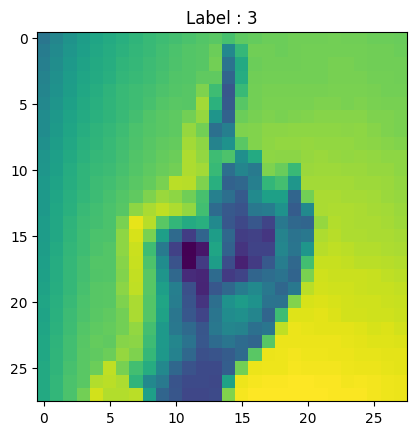

In [ ]:
X_train = train_df.drop("label", axis=1).values.reshape(-1, 28, 28, 1) / 255.0
y_train = train_df["label"].values

X_test = test_df.drop("label", axis=1).values.reshape(-1, 28, 28, 1) / 255.0
y_test = test_df["label"].values

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

plt.imshow(X_train[0].reshape(28, 28, 1))
plt.title(f"Label : {y_train[0]}")
plt.show()

In [ ]:
model = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3,3), activation="relu"),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation="relu"),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(25, activation="softmax")
])

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 25)             │         1,625 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,905 (480.10 KB)

 Trainable params: 122,905 (480.10 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer = keras.optimizers.Adam(learning_rate = 0.001),
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

In [ ]:
history = model.fit(
    X_train, y_train,
    epochs = 5,
    batch_size = 32,
    validation_split = 0.1
)

Epoch 1/5
773/773 ━━━━━━━━━━━━━━━━━━━━ 35s 43ms/step - accuracy: 0.6294 - loss: 1.2302 - val_accuracy: 0.8824 - val_loss: 0.3488
Epoch 2/5
773/773 ━━━━━━━━━━━━━━━━━━━━ 34s 43ms/step - accuracy: 0.9580 - loss: 0.1609 - val_accuracy: 0.9956 - val_loss: 0.0469
Epoch 3/5
773/773 ━━━━━━━━━━━━━━━━━━━━ 29s 38ms/step - accuracy: 0.9970 - loss: 0.0296 - val_accuracy: 0.9989 - val_loss: 0.0123
Epoch 4/5
773/773 ━━━━━━━━━━━━━━━━━━━━ 26s 34ms/step - accuracy: 0.9997 - loss: 0.0077 - val_accuracy: 1.0000 - val_loss: 0.0037
Epoch 5/5
773/773 ━━━━━━━━━━━━━━━━━━━━ 28s 36ms/step - accuracy: 0.9911 - loss: 0.0318 - val_accuracy: 1.0000 - val_loss: 0.0047


In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test loss : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.4f}")

225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.8943 - loss: 0.3665
Test loss : 0.3665
Test accuracy : 0.8943


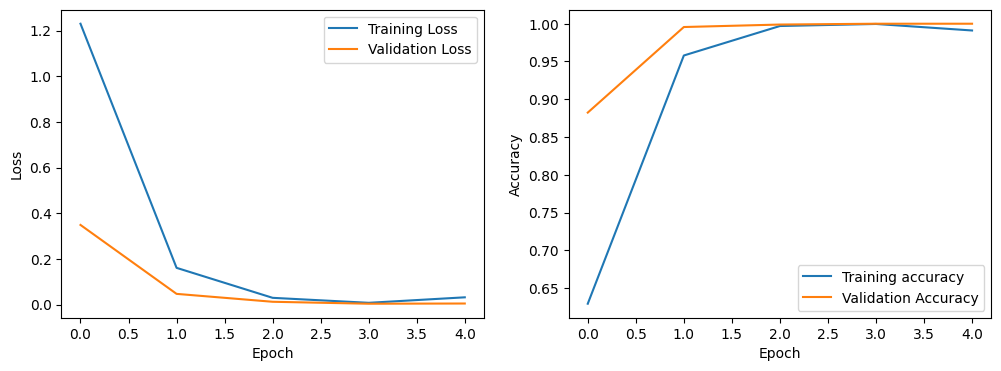

In [ ]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history["accuracy"], label = "Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()